# 03 — EDA, Analisis Temporal dan Insight

**Milestone 3 & Final | Analisis Big Data**

Gunakan data hasil `02_data_cleaning.ipynb`. Seluruh grafik berisi nilai terhitung, bukan angka contoh. Fokus analisis: tren jumlah publikasi, distribusi domain, label wilayah, pola hari, panjang artikel, dan variasi sumber antartahun.

**Batasan penting:** distribusi publikasi dalam dataset tidak dapat langsung disamakan dengan intensitas isu politik pada seluruh media Indonesia. Variasi cakupan scraping dan periode pengumpulan juga dapat memengaruhi hasil.

## 1. Library dan path data hasil cleaning

In [1]:
from pathlib import Path
import polars as pl
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Sesuaikan bila notebook ada di Colab sementara output ada di Drive:
PROCESSED_FILE_OVERRIDE = None
possible = [
    ROOT / "data" / "processed" / "political_news_analysis.parquet",
    Path.home() / "bigdata_teman" / "data" / "processed" / "political_news_analysis.parquet",
    Path("/content/drive/MyDrive/bigdata_teman/data/processed/political_news_analysis.parquet"),
]
PROCESSED_FILE = (Path(PROCESSED_FILE_OVERRIDE) if PROCESSED_FILE_OVERRIDE
                  else next((p for p in possible if p.exists()), possible[0]))
assert PROCESSED_FILE.is_file(), (
    f"Output cleaning tidak ditemukan: {PROCESSED_FILE}. "
    "Jalankan notebook 02 terlebih dahulu dan sesuaikan path jika memakai Colab."
)
FIG_DIR = ROOT / "output" / "figures"
TABLE_DIR = ROOT / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

lf = pl.scan_parquet(str(PROCESSED_FILE))
total = lf.select(pl.len()).collect().item()
print("Jumlah artikel siap analisis:", f"{total:,}")
print("Kolom:", lf.collect_schema())

def show_save(fig, filename):
    fig.update_layout(template="plotly_white", margin=dict(t=70, r=30, b=60, l=60))
    fig.show()
    fig.write_html(str(FIG_DIR / filename), include_plotlyjs="cdn", full_html=True)
    print("Grafik HTML:", FIG_DIR / filename)

Jumlah artikel siap analisis: 1,543,657
Kolom: Schema([('id', String), ('news_title', String), ('news_hostname', String), ('news_author', String), ('news_kabkot', String), ('publication_date', Date), ('publication_date_original', Date), ('date_out_of_range', Boolean), ('title_chars', UInt32), ('body_chars', UInt32), ('body_length_outlier', Boolean)])


## Grafik 1. Tren publikasi harian

In [6]:
from datetime import date

BATAS_TANGGAL = date(2026, 10, 15)

audit_temporal = lf.select([
    pl.len().alias("total_artikel"),
    pl.col("publication_date").is_null().sum().alias("tanggal_null"),
    (pl.col("publication_date") > BATAS_TANGGAL)
        .sum().alias("tanggal_masa_depan"),
]).collect()

print(audit_temporal)

shape: (1, 3)
┌───────────────┬──────────────┬────────────────────┐
│ total_artikel ┆ tanggal_null ┆ tanggal_masa_depan │
│ ---           ┆ ---          ┆ ---                │
│ u32           ┆ u32          ┆ u32                │
╞═══════════════╪══════════════╪════════════════════╡
│ 1543657       ┆ 403          ┆ 74                 │
└───────────────┴──────────────┴────────────────────┘


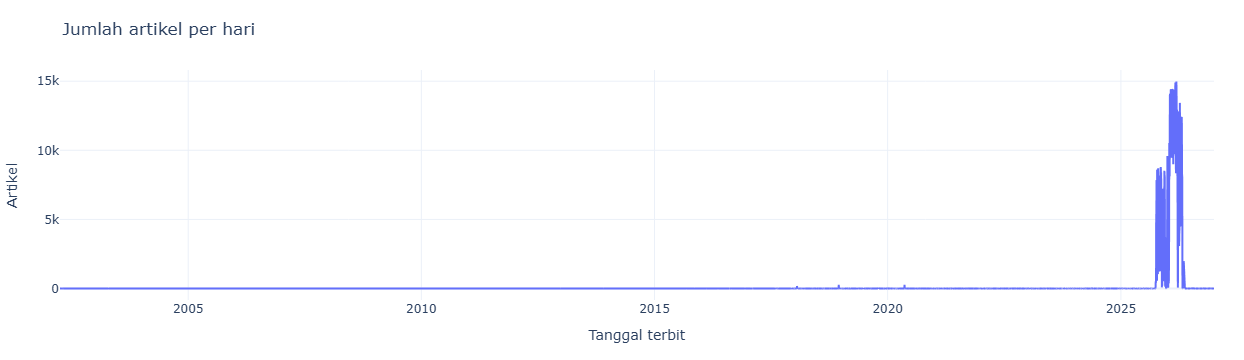

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\01_tren_harian.html


In [7]:
daily = (lf.group_by("publication_date").agg(pl.len().alias("jumlah"))
           .sort("publication_date").collect().to_pandas())
fig = px.line(daily, x="publication_date", y="jumlah", title="Jumlah artikel per hari",
              labels={"publication_date":"Tanggal terbit", "jumlah":"Artikel"})
show_save(fig, "01_tren_harian.html")

## Grafik 2. Tren publikasi bulanan

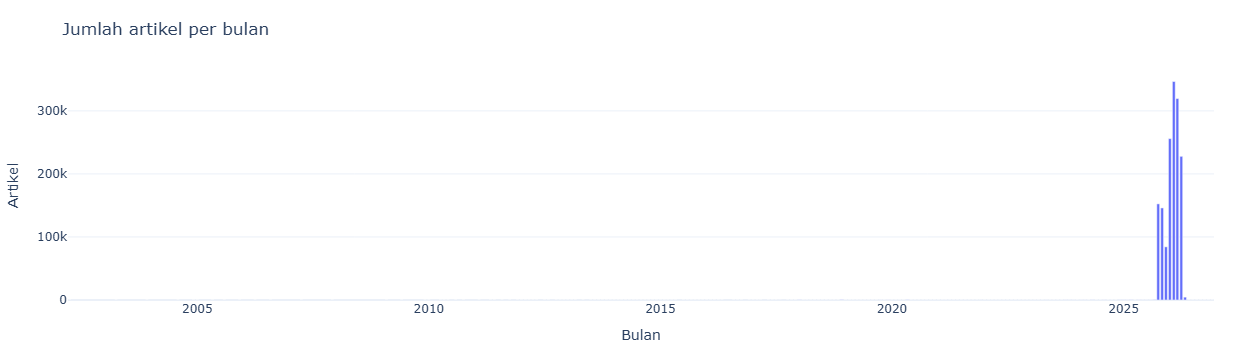

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\02_tren_bulanan.html


In [8]:
monthly = (lf.with_columns(pl.col("publication_date").dt.truncate("1mo").alias("bulan"))
             .group_by("bulan").agg(pl.len().alias("jumlah"))
             .sort("bulan").collect().to_pandas())
fig = px.bar(monthly, x="bulan", y="jumlah", title="Jumlah artikel per bulan",
             labels={"bulan":"Bulan", "jumlah":"Artikel"})
show_save(fig, "02_tren_bulanan.html")

## Grafik 3. Domain media terbanyak

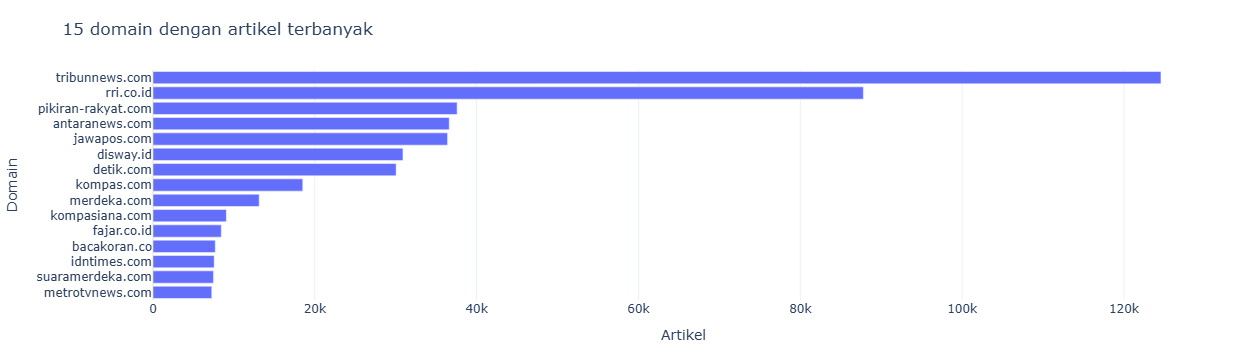

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\03_sumber_berita.html


In [9]:
hosts = (lf.group_by("news_hostname").agg(pl.len().alias("jumlah"))
         .sort("jumlah", descending=True).limit(15).collect().to_pandas())
fig = px.bar(hosts.sort_values("jumlah"), x="jumlah", y="news_hostname",
             orientation="h", title="15 domain dengan artikel terbanyak",
             labels={"news_hostname":"Domain", "jumlah":"Artikel"})
show_save(fig, "03_sumber_berita.html")

## Grafik 4. Label kabupaten/kota yang sering muncul

`news_kabkot` adalah atribut hasil pengolahan dataset. Grafik ini menunjukkan **frekuensi label wilayah**, bukan peta pasti lokasi kejadian.

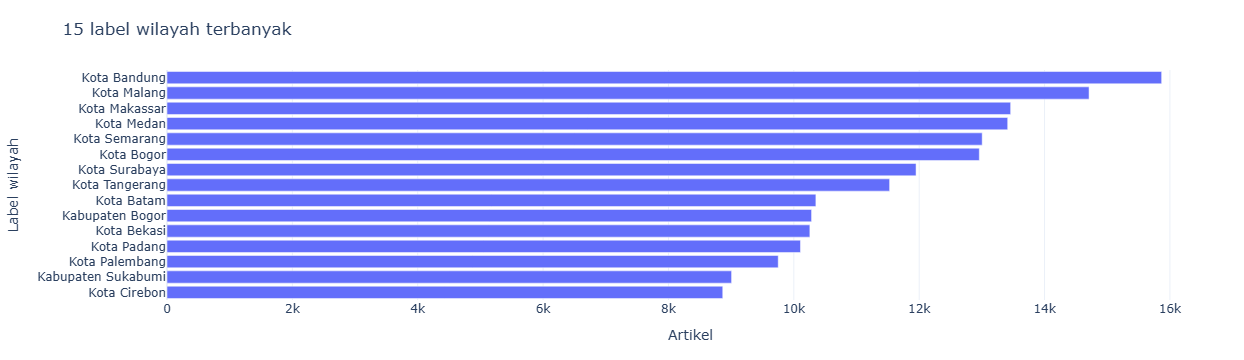

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\04_label_wilayah.html


In [10]:
regions = (lf.group_by("news_kabkot").agg(pl.len().alias("jumlah"))
           .sort("jumlah", descending=True).limit(15).collect().to_pandas())
fig = px.bar(regions.sort_values("jumlah"), x="jumlah", y="news_kabkot",
             orientation="h", title="15 label wilayah terbanyak",
             labels={"news_kabkot":"Label wilayah", "jumlah":"Artikel"})
show_save(fig, "04_label_wilayah.html")

## Grafik 5. Pola jumlah artikel menurut hari dalam minggu

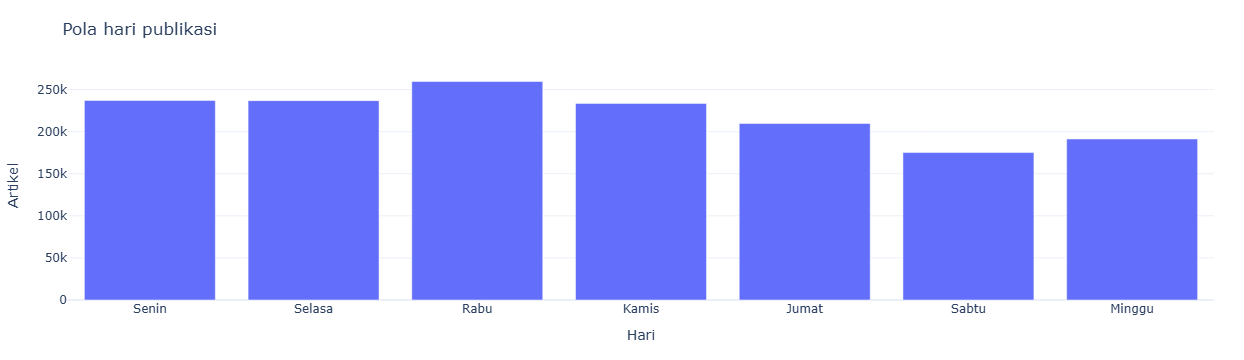

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\05_hari_publikasi.html


In [11]:
weekdays = (lf.with_columns(pl.col("publication_date").dt.weekday().alias("nomor_hari"))
            .group_by("nomor_hari").agg(pl.len().alias("jumlah"))
            .sort("nomor_hari").collect().to_pandas())
names = {1:"Senin", 2:"Selasa", 3:"Rabu", 4:"Kamis", 5:"Jumat", 6:"Sabtu", 7:"Minggu"}
weekdays["hari"] = weekdays["nomor_hari"].map(names)
fig = px.bar(weekdays, x="hari", y="jumlah", title="Pola hari publikasi",
             labels={"hari":"Hari", "jumlah":"Artikel"})
show_save(fig, "05_hari_publikasi.html")

## Grafik 6. Distribusi panjang isi artikel

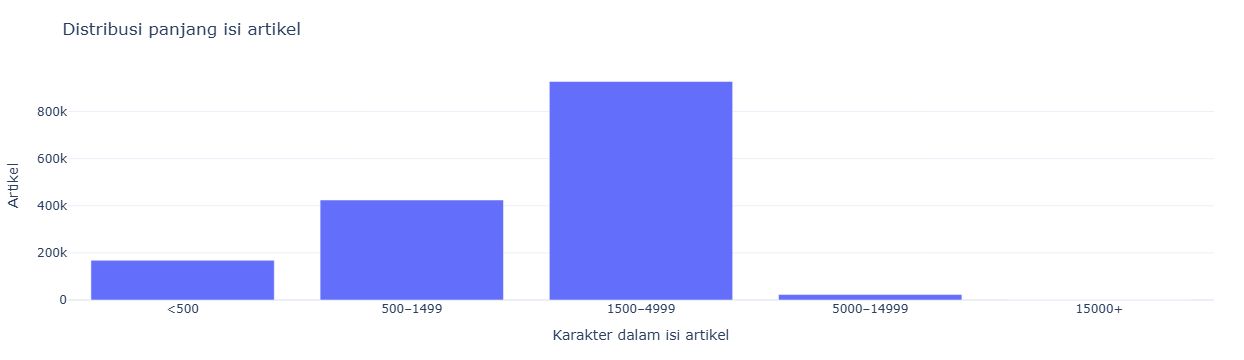

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\06_panjang_artikel.html


In [12]:
bins_lf = lf.with_columns(
    pl.when(pl.col("body_chars") < 500).then(pl.lit("<500"))
      .when(pl.col("body_chars") < 1500).then(pl.lit("500–1499"))
      .when(pl.col("body_chars") < 5000).then(pl.lit("1500–4999"))
      .when(pl.col("body_chars") < 15000).then(pl.lit("5000–14999"))
      .otherwise(pl.lit("15000+")).alias("kelompok_panjang")
)
length_bins = (bins_lf.group_by("kelompok_panjang").agg(pl.len().alias("jumlah"))
               .collect().to_pandas())
order = ["<500","500–1499","1500–4999","5000–14999","15000+"]
length_bins["kelompok_panjang"] = pd.Categorical(length_bins["kelompok_panjang"], categories=order, ordered=True)
length_bins = length_bins.sort_values("kelompok_panjang")
fig = px.bar(length_bins, x="kelompok_panjang", y="jumlah", title="Distribusi panjang isi artikel",
             labels={"kelompok_panjang":"Karakter dalam isi artikel", "jumlah":"Artikel"})
show_save(fig, "06_panjang_artikel.html")

## Grafik 7. Perbandingan sumber berita per tahun

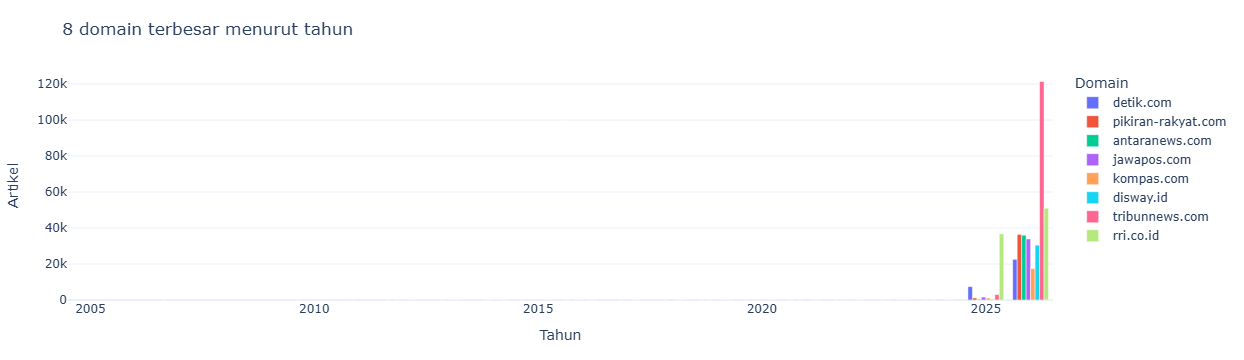

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\07_domain_per_tahun.html


In [13]:
top_hosts = hosts["news_hostname"].head(8).tolist()
host_year = (lf.filter(pl.col("news_hostname").is_in(top_hosts))
             .with_columns(pl.col("publication_date").dt.year().alias("tahun"))
             .group_by(["tahun", "news_hostname"])
             .agg(pl.len().alias("jumlah")).collect().to_pandas())
fig = px.bar(host_year, x="tahun", y="jumlah", color="news_hostname",
             barmode="group", title="8 domain terbesar menurut tahun",
             labels={"tahun":"Tahun", "jumlah":"Artikel", "news_hostname":"Domain"})
show_save(fig, "07_domain_per_tahun.html")

## Grafik 8. Persentase artikel berlabel outlier

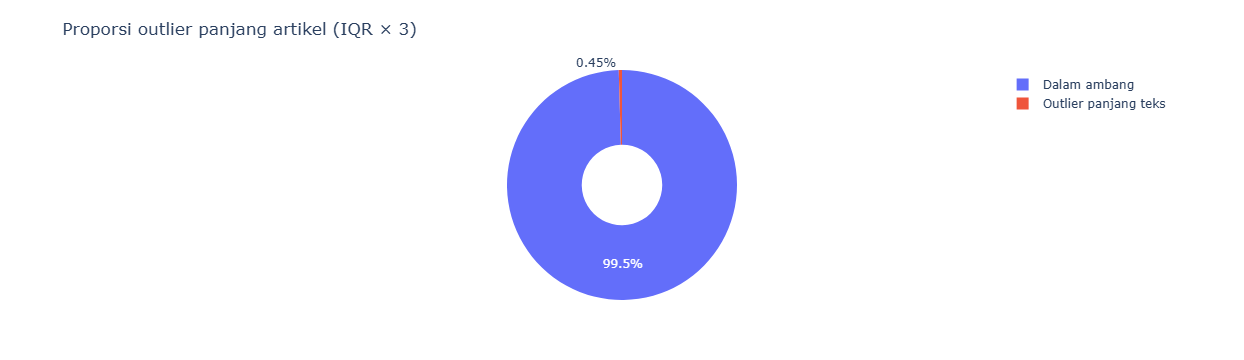

Grafik HTML: C:\Users\raihan bhakti\bigdata_teman\output\figures\08_outlier_artikel.html


In [14]:
outliers = (lf.group_by("body_length_outlier").agg(pl.len().alias("jumlah"))
            .collect().to_pandas())
outliers["status"] = outliers["body_length_outlier"].map({True:"Outlier panjang teks", False:"Dalam ambang"})
fig = px.pie(outliers, names="status", values="jumlah",
             title="Proporsi outlier panjang artikel (IQR × 3)", hole=0.35)
show_save(fig, "08_outlier_artikel.html")

## 5+ Insight yang dihitung dari data

Insight berikut **otomatis menggunakan hasil pengolahan saat notebook dijalankan**. Jangan menyalin kesimpulan sebelum angka grafik benar-benar keluar. Semua temuan bersifat deskriptif terhadap korpus dataset.

In [ ]:
peak_month = monthly.loc[monthly["jumlah"].idxmax()]
top_host = hosts.iloc[0]
top_region = regions.iloc[0]
weekday_peak = weekdays.loc[weekdays["jumlah"].idxmax()]
med_chars = lf.select(pl.col("body_chars").median()).collect().item()
num_outlier = lf.select(pl.col("body_length_outlier").sum()).collect().item()
region_unknown = lf.filter(pl.col("news_kabkot") == "Tidak tersedia").select(pl.len()).collect().item()

insights = [
    f"Bulan dengan jumlah artikel terbesar pada korpus ini adalah {pd.Timestamp(peak_month['bulan']).strftime('%Y-%m')} sebanyak {int(peak_month['jumlah']):,} artikel.",
    f"Domain {top_host['news_hostname']} muncul paling banyak, yaitu {int(top_host['jumlah']):,} artikel ({100*top_host['jumlah']/total:.2f}% dari korpus bersih).",
    f"Label wilayah yang paling sering muncul adalah {top_region['news_kabkot']} dengan {int(top_region['jumlah']):,} artikel. Label ini bukan verifikasi lokasi peristiwa.",
    f"Hari publikasi terbanyak berdasarkan tanggal yang tercantum adalah {weekday_peak['hari']} dengan {int(weekday_peak['jumlah']):,} artikel.",
    f"Median panjang isi artikel adalah {med_chars:,.0f} karakter, menggambarkan artikel tengah menurut panjang teks.",
    f"Artikel yang ditandai sebagai outlier panjang isi berjumlah {int(num_outlier):,} ({100*num_outlier/total:.2f}%); outlier tidak otomatis dianggap salah.",
    f"Artikel dengan label wilayah tidak tersedia berjumlah {int(region_unknown):,} ({100*region_unknown/total:.2f}%).",
]

for i, insight in enumerate(insights,1):
    print(f"{i}. {insight}")

insight_path = TABLE_DIR / "insights.md"
insight_path.write_text("# Insight Analitik\n\n" + "\n".join(f"{i}. {s}" for i,s in enumerate(insights,1)), encoding="utf-8")
print("Disimpan:", insight_path)

## Kesimpulan dan keterbatasan

Simpan grafik hasil eksekusi di `output/figures/` dan periksa minimal lima insight tercetak berdasarkan data. Temuan bisa bias oleh cakupan situs, waktu pengambilan, serta pembersihan yang telah dilakukan oleh pemilik dataset. Distribusi label `news_kabkot` tidak otomatis merepresentasikan kepadatan berita secara geografis yang sesungguhnya.